# scATAC TF-motif and accessibility concordance (Figure 4)

Reads tables from `../data/` and writes figures to `../output/`. Source notebook is listed in `../../NOTEBOOK_PROVENANCE.tsv`.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output


✓ Imports and style configured.
✓ Configuration loaded.
✓ String helpers defined.
✓ Matrix & clustering helpers defined.
✓ Category & ordering helpers defined.
✓ MEME parser defined.
✓ TF→motif mapping function defined.
✓ Logo renderer defined.
✓ Split-triangle renderer defined.
all_df shape : (1122, 18)
sig_tf shape : (22, 8)
Significant TFs : 22
After filtering : 22 unique rows, 102 comparisons
Matrix shape after variance filter : (22, 102)
Final matrix : 22 TFs × 102 comparisons
Final matrix: 22 TFs × 102 comparisons
Loading JASPAR MEME file …
  Loaded 892 motifs
  Mapped 22/22 TFs to motifs
  Rendered logos for 22 TFs
Panels : ['r ≥ 0', 'r < 0']
  'r ≥ 0' : 16 TFs
  'r < 0' : 6 TFs
Figure size: 20.2 × 9.3 inches
✓ Figure layout created.
motif vmax: 0.9814853751952524
motif min: -0.9814853751952524
access vmax: 2.0971384300518263
access min: -4.642199403418949
✓ Category strip & colour scales ready.
✓ All panels drawn.


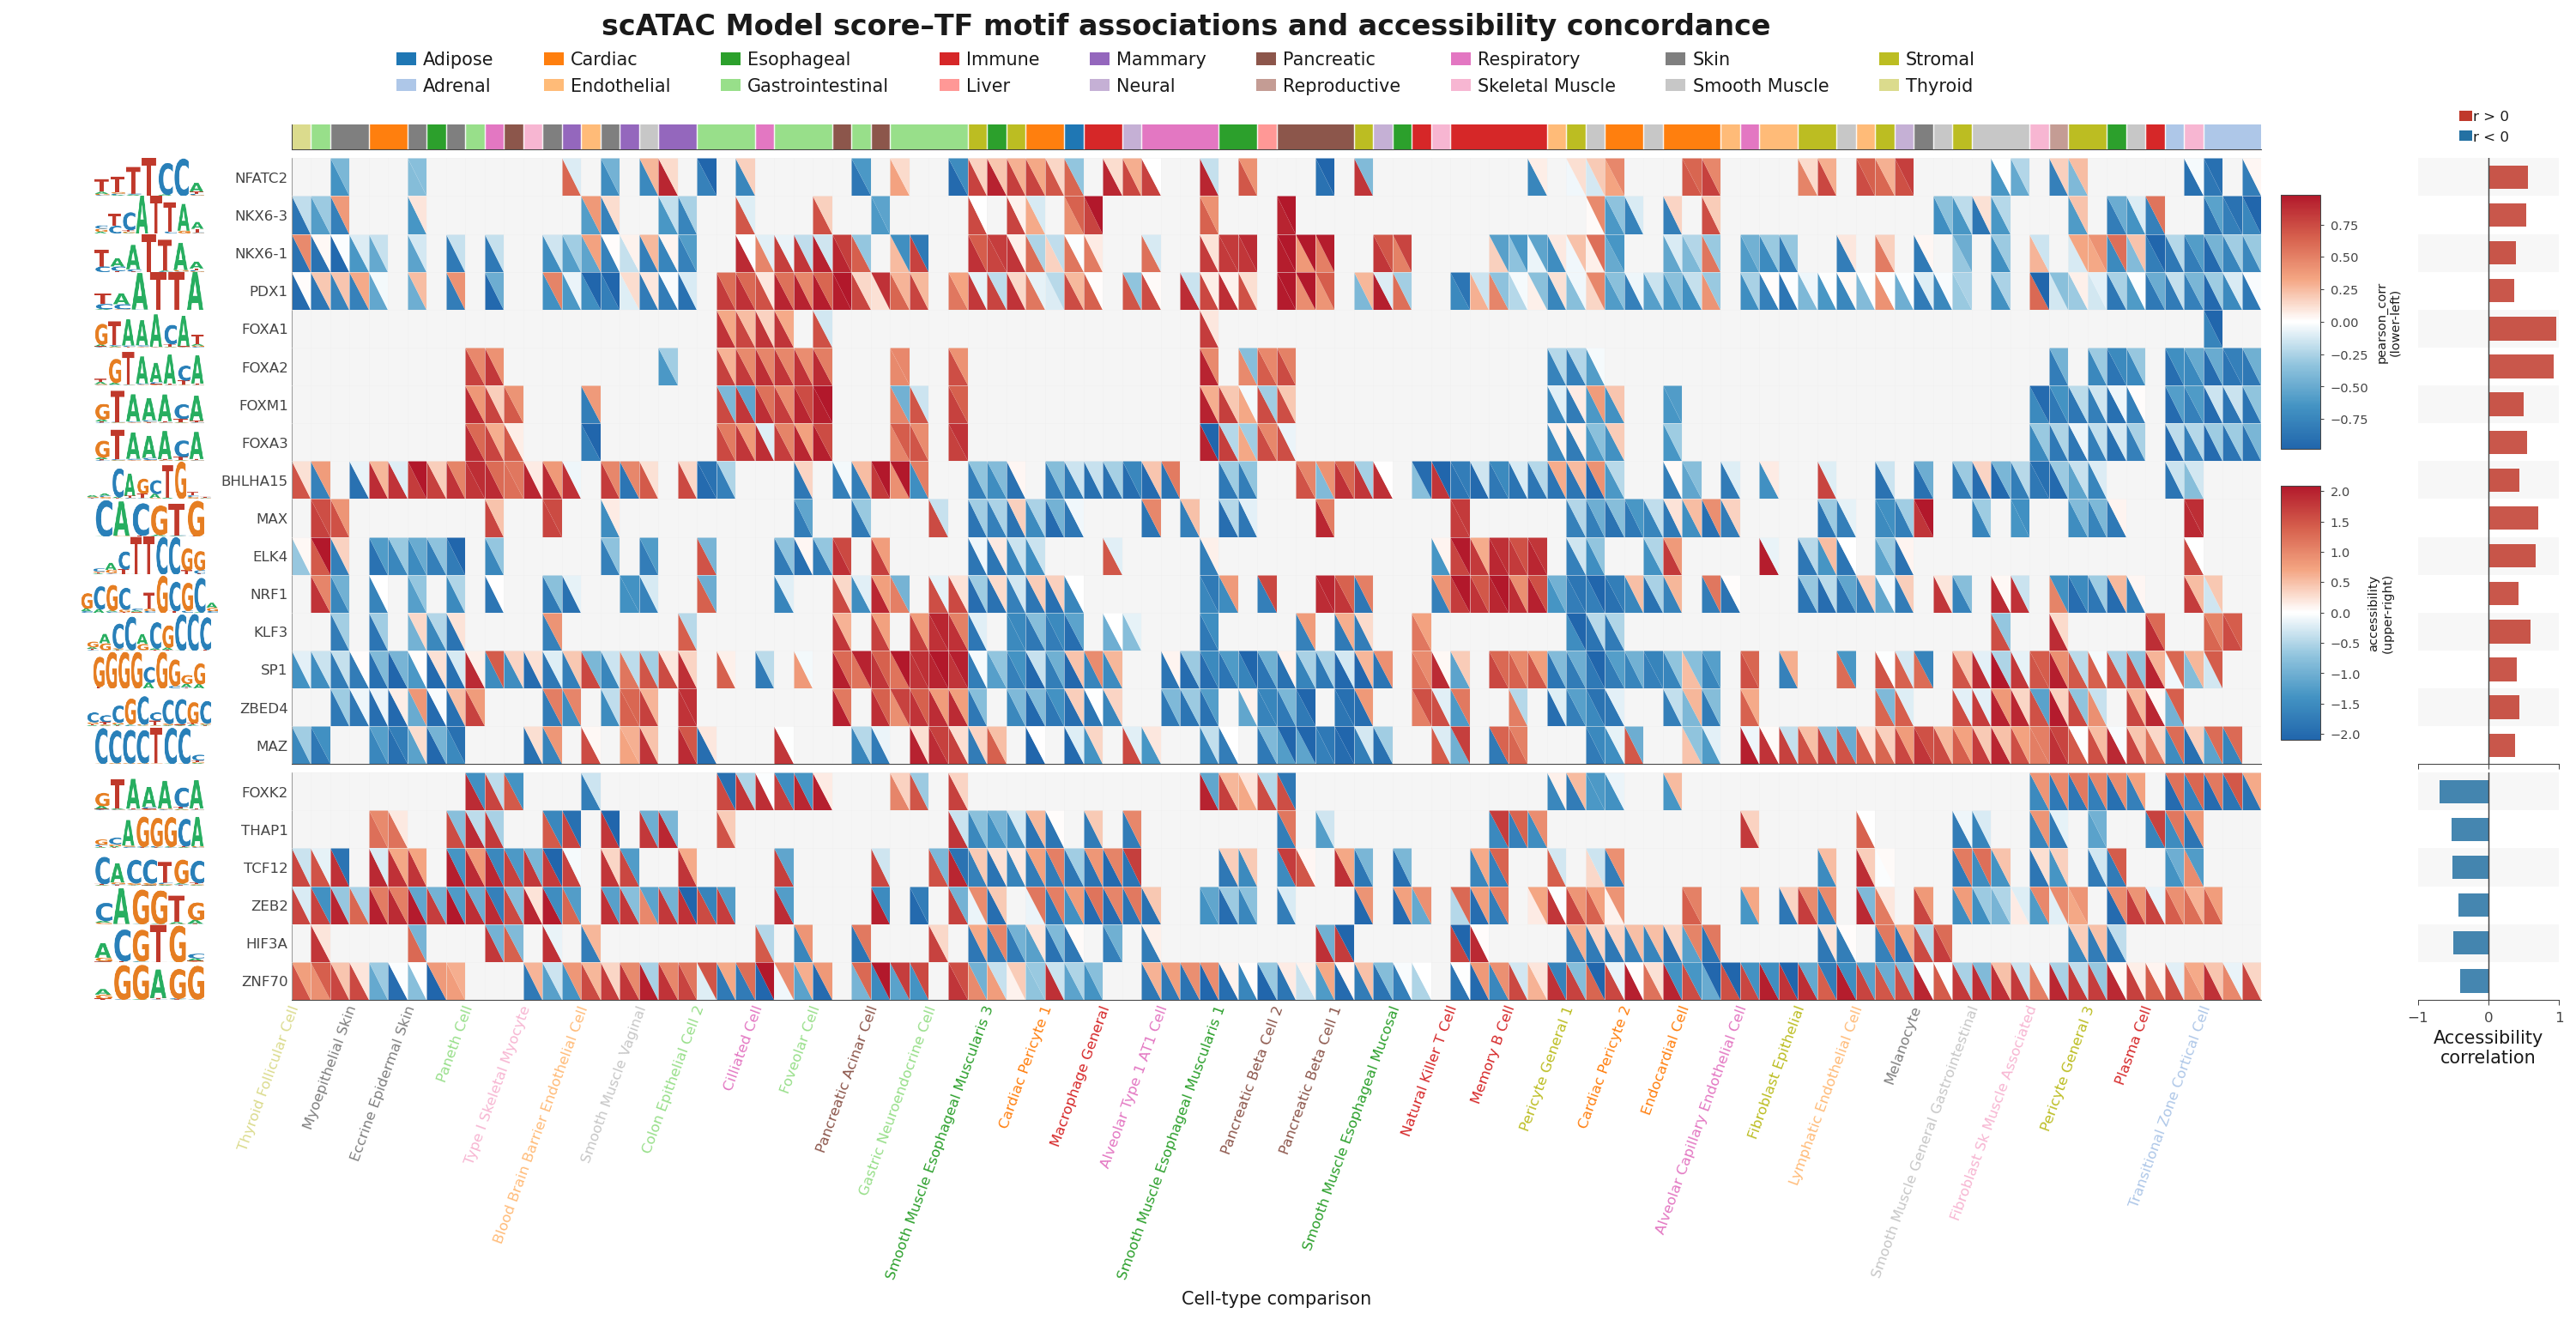

Saved → /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_tf_motif_accessibility.png
Saved → /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/scatac/output/scatac_tf_motif_accessibility.pdf


In [2]:
import io
import re
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from matplotlib.patches import PathPatch
from matplotlib.textpath import TextPath
from matplotlib.transforms import Affine2D
from matplotlib.font_manager import FontProperties
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import pdist

# ── Colour palette ────────────────────────────────────────────────
FIG_BG   = "white"
SPINE_C  = "#444444"
TICK_C   = "#444444"
LABEL_C  = "#1a1a1a"
GRID_C   = "#eeeeee"
POS_C    = "#c0392b"   # red  – positive Pearson r
NEG_C    = "#2471a3"   # blue – negative Pearson r

# DNA base colours for sequence logos
BASE_COLORS = {"A": "#27ae60", "C": "#2980b9", "G": "#e67e22", "T": "#c0392b"}

# Diverging colormap: blue → white → red
HEATMAP_CMAP = LinearSegmentedColormap.from_list(
    "pub_div",
    ["#2166ac", "#4393c3", "#92c5de", "#ffffff", "#f4a582", "#d6604d", "#b2182b"],
    N=512,
)

# Apply global matplotlib style for publication-quality output
plt.rcParams.update({
    "figure.facecolor":  FIG_BG,
    "axes.facecolor":    FIG_BG,
    "axes.edgecolor":    SPINE_C,
    "axes.labelcolor":   LABEL_C,
    "axes.titlecolor":   LABEL_C,
    "text.color":        LABEL_C,
    "xtick.color":       TICK_C,
    "ytick.color":       TICK_C,
    "xtick.labelsize":   10,
    "ytick.labelsize":   10,
    "axes.linewidth":    0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size":  3,
    "ytick.major.size":  3,
    "font.family":       "sans-serif",
    "font.sans-serif":   ["Helvetica", "Arial", "DejaVu Sans"],
    "pdf.fonttype":      42,  # embed fonts as TrueType in PDF
    "ps.fonttype":       42,
    "savefig.dpi":       300,
})

print("✓ Imports and style configured.")
# ── File paths ────────────────────────────────────────────────────────────────
DATA_DIR = str(DATA)
OUT_DIR = OUT
ALL_TSV = f"{DATA_DIR}/all_results_full_with_accessibility_long_sigTFs.tsv"
SIG_TF_TSV = f"{DATA_DIR}/pearson_corr_A_sigTFs.tsv"

JASPAR_MEME = f"{DATA_DIR}/20260216202920_JASPAR2026_combined_matrices_1336868.meme"
JASPAR_ANNOT = f"{DATA_DIR}/motifs_annotations_full.txt"
CATEGORY_MAP_TSV = f"{DATA_DIR}/category_map.tsv"
TF_MOTIF_OVERRIDE_TSV = None   # Optional TSV: columns tf, jaspar_id
ACCESSIBILITY_MATRIX_TSV = None  # Optional: TF × comparison accessibility matrix

# ── Column names ──────────────────────────────────────────────────────────────
VALUE_COL       = "pearson_corr"   # choices: pearson_corr | signed_zscore | signed_mi
COMPARISON_COL  = "comparison"
MOTIF_COL       = "motif_name"
ALL_TF_COL      = "tf"             # If this column exists in all_tsv, use it directly
SIG_TF_COL      = "tf"
SIG_TF_R_COL    = "pearson_r"
ACCESSIBILITY_COL = "accessibility"
ACCESSIBILITY_AGG = "mean"         # mean | abs_max | max | min

# ── Filtering & ordering ──────────────────────────────────────────────────────
TOP_N            = 120    # Keep top-N TFs by |Pearson r|
MIN_COMPARISONS  = 1      # Min number of comparisons a TF must appear in
NO_CLUSTER       = False  # Set True to skip hierarchical clustering
NO_LOGOS         = False  # Set True to skip JASPAR sequence logos
NO_SPLIT_POS_NEG = False  # Set True to merge pos/neg panels
SPLIT_TRIANGLE   = True  # Set True for split-triangle motif+accessibility cells

# Column order: 'cluster' | 'category' | 'category_cluster'
COLUMN_ORDER        = "cluster"
COL_CLUSTER_METRIC  = "cosine"  # correlation | cosine | euclidean | cityblock
COL_LINKAGE_METHOD  = "average"      # average | complete | ward | single
ROW_CLUSTER_METRIC  = "cosine"
ROW_LINKAGE_METHOD  = "average"
CLUSTER_ROW_ZSCORE  = False 
CLUSTER_SOURCE      = "combined"  # motif | accessibility | combined

# ── Visual tweaks ─────────────────────────────────────────────────────────────
TITLE            = None    # Set to a string to override the auto title
MAX_XLABELS      = 36      # Maximum x-axis labels shown (auto-thinned beyond this)
X_LABEL_ROTATION = 70.0    # Degrees
LOGO_ZOOM        = 0.28    # Scaling factor for JASPAR logos
MAX_LOGO_ROWS    = 120     # Maximum rows to draw logos for
BAR_GAP          = 0.06    # Gap (figure fraction) between heatmap and bar chart
MOTIF_CMAP       = "pub_div"   # 'pub_div' uses HEATMAP_CMAP; else any matplotlib name
ACCESSIBILITY_CMAP = "pub_div" # RdBu_r
ACCESSIBILITY_SCALE = "none"  # per_tf | none

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("✓ Configuration loaded.")
### 2a. Normalisation & string utilities
def normalize_tf(s):
    """Upper-case + strip a TF symbol; return '' for NaN."""
    if pd.isna(s):
        return ""
    return str(s).strip().upper()


def split_tf_list(s):
    """Split a '|'-delimited TF list string into a list of normalised symbols."""
    if pd.isna(s):
        return []
    return [normalize_tf(x) for x in str(s).split("|") if str(x).strip()]


def comp_to_celltype(comp):
    """Strip the trailing '_vs_all' suffix from a comparison label to get cell-type name."""
    if pd.isna(comp):
        return ""
    return re.sub(r"_vs_all$", "", str(comp).strip())


def extract_tf_tokens(text):
    """
    Tokenise a motif/TF name into meaningful alpha-numeric tokens.
    Removes JASPAR matrix IDs (e.g. MA0001.1) and short tokens.
    """
    if not text:
        return []
    s = normalize_tf(str(text)).replace("::", " ")
    s = re.sub(r"[^A-Z0-9]+", " ", s)
    toks = [t for t in s.split() if len(t) >= 2]
    return [t for t in toks if not re.match(r"^MA\d+(\.\d+)?$", t)]


print("✓ String helpers defined.")
### 2b. Matrix construction & clustering
def build_matrix(df, index_col, col_col, value_col):
    """
    Pivot df into a TF × comparison matrix.
    When multiple rows share the same (TF, comparison), keep the value with the
    largest absolute magnitude (abs_max aggregation).
    """
    def abs_max(s):
        s = s.dropna()
        return s.iloc[int(s.abs().argmax())] if len(s) else np.nan
    return df.pivot_table(
        index=index_col, columns=col_col,
        values=value_col, aggfunc=abs_max
    )


def cluster_order(x, axis, metric="correlation", method="average"):
    """
    Return the leaf order from hierarchical clustering of rows (axis=0)
    or columns (axis=1) of DataFrame x.
    Falls back to original order for degenerate inputs.
    """
    arr = x.values if axis == 0 else x.values.T
    if arr.shape[0] <= 1:
        return np.arange(arr.shape[0])
    use_metric = metric
    use_method = method
    if method == "ward" and metric != "euclidean":
        use_metric = "euclidean"   # ward requires Euclidean distances
    d = pdist(arr, metric=use_metric)
    if np.allclose(d, 0):
        return np.arange(arr.shape[0])
    return leaves_list(linkage(d, method=use_method))


def row_zscore(df):
    """Z-score each row independently (subtract mean, divide by std)."""
    out = df.copy().astype(float)
    mu  = out.mean(axis=1)
    sd  = out.std(axis=1).replace(0, 1.0)
    return out.sub(mu, axis=0).div(sd, axis=0)


def scale_accessibility_per_tf(acc_df, motif_df):
    """
    Scale each TF's accessibility row so its max absolute value matches
    the corresponding motif score range.  Avoids colour-scale mismatch
    when overlaying motif and accessibility in split-triangle cells.
    """
    acc = acc_df.copy().astype(float)
    motif_abs = motif_df.abs().max(axis=1).replace(0, np.nan)
    acc_abs   = acc.abs().max(axis=1).replace(0, np.nan)
    scale = motif_abs / acc_abs
    acc   = acc.mul(scale, axis=0)
    return acc.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def zscore_accessibility_per_tf(acc_df):
    """
    Z-score normalize accessibility per TF (row-wise).

    This centers each TF's accessibility values at 0 and scales
    by the standard deviation so that the heatmap shows relative
    increases and decreases across comparisons.

    Useful when accessibility values are strictly positive and
    need to be visually comparable to signed motif scores.
    """
    acc = acc_df.copy().astype(float)

    mean = acc.mean(axis=1)
    std  = acc.std(axis=1).replace(0, np.nan)

    acc_z = acc.sub(mean, axis=0).div(std, axis=0)

    return acc_z.replace([np.inf, -np.inf], np.nan).fillna(0.0)

def center_white_cmap(cmap, name=None, n=257):
    """
    Return a modified colormap that has pure white exactly at the midpoint (0.5).
    This ensures the zero-crossing always renders as white on the heatmap.
    """
    if isinstance(cmap, str):
        cmap = cm.get_cmap(cmap)
    n = int(n) if n else 257
    if n % 2 == 0:
        n += 1
    half  = n // 2
    lower = cmap(np.linspace(0.0, 0.5, half, endpoint=False))
    upper = cmap(np.linspace(0.5, 1.0, half, endpoint=True))
    colors = np.vstack([lower, np.array([[1, 1, 1, 1]]), upper])
    return LinearSegmentedColormap.from_list(
        name or f"{cmap.name}_white0", colors, N=len(colors)
    )


print("✓ Matrix & clustering helpers defined.")
### 2c. Category map loading
def load_category_map(path):
    """
    Load a TSV with columns [celltype, category] and return a dict.
    Returns None if path is falsy.
    """
    if not path:
        return None
    df = pd.read_csv(path, sep="\t")
    if not {"celltype", "category"}.issubset(df.columns):
        raise ValueError("category map TSV must have columns: celltype, category")
    return dict(zip(df["celltype"].astype(str), df["category"].astype(str)))


def load_tf_motif_override(path):
    """
    Load a TSV with columns [tf, jaspar_id] for manual TF→motif mapping.
    Returns {} if path is falsy.
    """
    if not path:
        return {}
    df = pd.read_csv(path, sep="\t")
    if not {"tf", "jaspar_id"}.issubset(df.columns):
        raise ValueError("override TSV must have columns: tf, jaspar_id")
    return dict(zip(df["tf"].map(normalize_tf), df["jaspar_id"].astype(str)))


def reorder_columns(x, cluster_x, cat_series, order_mode, no_cluster,
                    metric="correlation", method="average"):
    """
    Determine final column order based on order_mode.

    order_mode options:
      'cluster'          – global hierarchical clustering of all columns
      'category'         – sort by category label alphabetically, no within-cluster
      'category_cluster' – sort by category, then cluster within each category
    """
    cols = list(x.columns)
    if order_mode == "cluster" or cat_series is None:
        if no_cluster or len(cols) <= 1:
            return cols
        return list(np.array(cols)[
            cluster_order(cluster_x[cols], 1, metric=metric, method=method)
        ])

    cat_series = cat_series.reindex(cols)
    category_keys = sorted(cat_series.dropna().unique().tolist())
    if cat_series.isna().any():
        category_keys.append("__UNMAPPED__")

    ordered = []
    for cat in category_keys:
        ccols = ([c for c in cols if pd.isna(cat_series.loc[c])]
                 if cat == "__UNMAPPED__"
                 else [c for c in cols if cat_series.loc[c] == cat])
        if not ccols:
            continue
        if order_mode == "category_cluster" and (not no_cluster) and len(ccols) > 1:
            ordered.extend(list(np.array(ccols)[
                cluster_order(cluster_x[ccols], 1, metric=metric, method=method)
            ]))
        else:
            ordered.extend(ccols)
    return ordered


print("✓ Category & ordering helpers defined.")
### 2d. MEME file parser
def parse_meme_file(meme_path: Path) -> dict:
    """
    Parse a MEME-format file and return a dict:
        { motif_id: {"name": str, "ppm": np.ndarray (L×4)} }
    where columns of ppm correspond to A, C, G, T.
    """
    motifs   = {}
    cur_id   = cur_name = None
    cur_rows = []

    with meme_path.open() as f:
        lines = f.readlines()

    i = 0
    while i < len(lines):
        line = lines[i].strip()

        if line.startswith("MOTIF "):
            # Flush previous motif
            if cur_id and cur_rows:
                motifs[cur_id] = {"name": cur_name,
                                  "ppm":  np.array(cur_rows, dtype=float)}
            parts    = line.split(maxsplit=2)
            cur_id   = parts[1] if len(parts) > 1 else None
            cur_name = parts[2] if len(parts) > 2 else cur_id
            cur_rows = []
            i += 1
            continue

        if line.startswith("letter-probability matrix"):
            i += 1
            while i < len(lines):
                row = lines[i].strip()
                if not row or row.startswith("MOTIF "):
                    if row.startswith("MOTIF "):
                        i -= 1  # re-process MOTIF line on next outer iteration
                    break
                vals = row.split()
                if len(vals) >= 4:
                    try:
                        cur_rows.append([float(v) for v in vals[:4]])
                    except ValueError:
                        pass
                i += 1
        i += 1

    # Flush the last motif
    if cur_id and cur_rows:
        motifs[cur_id] = {"name": cur_name, "ppm": np.array(cur_rows, dtype=float)}

    return motifs


print("✓ MEME parser defined.")
### 2e. TF → JASPAR motif mapping
def build_tf_to_motif_map(
    meme_motifs: dict,
    annot_path: Path,
    target_tfs: set,
    override_map=None
) -> tuple:
    """
    Map each TF symbol → best JASPAR motif ID.

    Matching priority (highest → lowest):
      0) Manual override table (--tf-motif-override-tsv)
      1) Exact token match in PWM name
      2) Exact token match in annotation Display_Name
      3) Prefix match in PWM name token
      4) Substring match in full PWM name string

    Returns
    -------
    tf_to_id     : dict  tf → motif_id
    tf_source    : dict  tf → source_string (for auditing)
    """
    tf_to_id: dict = {}
    tf_source: dict = {}
    override_map = override_map or {}

    # Pass 0: manual overrides have highest priority
    for tf in sorted(target_tfs):
        mid = override_map.get(tf)
        if mid and mid in meme_motifs:
            tf_to_id[tf]  = mid
            tf_source[tf] = "override"

    # Build reverse look-up indexes from MEME motif names
    tok_to_mid: dict  = {}   # exact token → motif id
    pre_to_mids: dict = {}   # prefix → list of motif ids
    sub_entries: list = []   # (full_name_upper, mid) for substring search

    for mid, rec in meme_motifs.items():
        full_name = str(rec.get("name", ""))
        full_up   = normalize_tf(full_name)
        sub_entries.append((full_up, mid))
        for tok in extract_tf_tokens(full_name) + extract_tf_tokens(mid):
            tok_to_mid.setdefault(tok, mid)
            for plen in range(4, len(tok) + 1):
                pre_to_mids.setdefault(tok[:plen], []).append(mid)

    # Pass 1: exact PWM-name token match
    for tf in target_tfs:
        if tf not in tf_to_id and tf in tok_to_mid:
            tf_to_id[tf]  = tok_to_mid[tf]
            tf_source[tf] = "pwm_name_exact"

    # Pass 2: annotation table token match
    if annot_path.exists():
        ann      = pd.read_csv(annot_path, sep="\t")
        id_col   = "JASPAR_ID"    if "JASPAR_ID"    in ann.columns else ann.columns[0]
        name_col = "Display_Name" if "Display_Name" in ann.columns else ann.columns[1]
        for _, row in ann.iterrows():
            mid = str(row[id_col])
            if mid not in meme_motifs:
                continue
            for tok in extract_tf_tokens(str(row[name_col])):
                if tok in target_tfs and tok not in tf_to_id:
                    tf_to_id[tok]  = mid
                    tf_source[tok] = "annotation_exact"

    # Pass 3: prefix match
    for tf in target_tfs:
        if tf in tf_to_id:
            continue
        cands = pre_to_mids.get(tf, [])
        if cands:
            tf_to_id[tf]  = cands[0]
            tf_source[tf] = "pwm_name_prefix"

    # Pass 4: substring match (most lenient)
    for tf in target_tfs:
        if tf in tf_to_id:
            continue
        for full_name_up, mid in sub_entries:
            if tf in full_name_up:
                tf_to_id[tf]  = mid
                tf_source[tf] = "pwm_name_substring"
                break

    missing = target_tfs - set(tf_to_id.keys())
    if missing:
        print(f"  [logo] No JASPAR motif found for: {sorted(missing)}")

    return tf_to_id, tf_source


print("✓ TF→motif mapping function defined.")
### 2f. Sequence logo renderer
def ppm_to_logo_array(ppm: np.ndarray) -> np.ndarray | None:
    """
    Render a position-probability matrix (PPM) as a sequence logo.

    Letters are scaled by information content (bits).
    Returns an RGBA image array (H×W×4, float 0-1) or None on failure.
    """
    if ppm is None or len(ppm) == 0:
        return None

    try:
        from PIL import Image
        use_pil = True
    except ImportError:
        use_pil = False

    ppm = np.clip(np.asarray(ppm, dtype=float), 1e-9, None)
    ppm = ppm / ppm.sum(axis=1, keepdims=True)
    n   = ppm.shape[0]  # number of positions

    with plt.rc_context({"figure.facecolor": "white", "axes.facecolor": "white"}):
        fig2, ax2 = plt.subplots(figsize=(max(2.2, n * 0.25), 0.75), dpi=100)
        fp = FontProperties(weight="bold", family="sans-serif")

        for i in range(n):
            p    = ppm[i]
            info = max(0.0, 2.0 + np.sum(p * np.log2(p)))  # information content in bits
            y    = 0.0
            # Draw bases sorted by height (smallest at bottom for clarity)
            for base, h in sorted(zip("ACGT", p * info), key=lambda kv: kv[1]):
                if h <= 1e-4:
                    continue
                tp = TextPath((0, 0), base, size=1, prop=fp)
                bb = tp.get_extents()
                if bb.width <= 0 or bb.height <= 0:
                    continue
                trans = (Affine2D()
                         .scale(0.88 / bb.width, h / bb.height)
                         .translate(i + 0.06, y))
                ax2.add_patch(PathPatch(
                    tp, transform=trans + ax2.transData,
                    lw=0, color=BASE_COLORS[base]
                ))
                y += h

        ax2.set_xlim(0, n); ax2.set_ylim(0, 2); ax2.axis("off")
        fig2.tight_layout(pad=0)

        buf = io.BytesIO()
        fig2.savefig(buf, format="png", dpi=100, transparent=False,
                     bbox_inches="tight", pad_inches=0, facecolor="white")
        plt.close(fig2)

    buf.seek(0)
    if use_pil:
        return np.array(Image.open(buf)).astype(float) / 255.0
    return plt.imread(buf)


print("✓ Logo renderer defined.")
### 2g. Split-triangle heatmap renderer
def draw_split_triangle_heatmap(
    ax, left_df, right_df, left_norm, right_norm,
    left_cmap, right_cmap, missing_color = "#f5f5f5"
):
    """
    Draw a heatmap where each cell is split diagonally into two triangles.

    Lower-left triangle → motif score  (left_df, left_cmap)
    Upper-right triangle → accessibility (right_df, right_cmap)

    NaN values are shown in missing_color.
    """
    n_rows, n_cols = left_df.shape
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_facecolor("white")

    for i in range(n_rows):
        for j in range(n_cols):
            lv = left_df.iat[i, j] # motif score
            rv = right_df.iat[i, j] # accessibility
            motif_missing = not np.isfinite(lv)
            if motif_missing:
                ax.add_patch(mpatches.Rectangle(
                    (j, i), 1, 1,
                    facecolor=missing_color, edgecolor="none"
                ))
                continue
            
            lc = left_cmap(left_norm(lv))  if np.isfinite(lv) else missing_color
            rc = right_cmap(right_norm(rv)) if np.isfinite(rv) else missing_color
        
            # Lower-left triangle: motif score
            ax.add_patch(mpatches.Polygon(
                [(j, i), (j, i + 1), (j + 1, i + 1)],
                closed=True, facecolor=lc, edgecolor="none"
            ))
            # Upper-right triangle: accessibility
            ax.add_patch(mpatches.Polygon(
                [(j, i), (j + 1, i), (j + 1, i + 1)],
                closed=True, facecolor=rc, edgecolor="none"
            ))

    # Subtle grid lines
    for c in range(n_cols + 1):
        ax.axvline(c, color="#f0f0f0", lw=0.25, zorder=5)
    for r in range(n_rows + 1):
        ax.axhline(r, color="#f0f0f0", lw=0.25, zorder=5)


print("✓ Split-triangle renderer defined.")
# ── Load raw data tables ──────────────────────────────────────────────────────
all_df = pd.read_csv(ALL_TSV, sep="\t")
sig_tf = pd.read_csv(SIG_TF_TSV, sep="\t")

print(f"all_df shape : {all_df.shape}")
print(f"sig_tf shape : {sig_tf.shape}")

# Row mode: 'TF' extracts TF symbols from motif names (default)
#           'MOTIF' uses raw motif_name strings as row identifiers
ROW_MODE = "TF"

sig_tf = sig_tf[[SIG_TF_COL, SIG_TF_R_COL]].copy()
sig_tf["tf_norm"] = sig_tf[SIG_TF_COL].map(normalize_tf)
sig_tf = (
    sig_tf
    .dropna(subset=["tf_norm"])
    .drop_duplicates("tf_norm", keep="first")
)
print(f"Significant TFs : {len(sig_tf)}")

# ── Prepare main data frame ───────────────────────────────────────────────────
has_all_tf = ALL_TF_COL in all_df.columns
has_acc    = ACCESSIBILITY_COL in all_df.columns

df_cols = [MOTIF_COL, COMPARISON_COL, VALUE_COL]
if has_all_tf:
    df_cols.append(ALL_TF_COL)
if has_acc:
    df_cols.append(ACCESSIBILITY_COL)

df = all_df.loc[~all_df[VALUE_COL].isna(), df_cols].copy()

# Assign row_id per ROW_MODE
if ROW_MODE == "TF":
    if has_all_tf:
        df["row_id"] = df[ALL_TF_COL].map(normalize_tf)
    else:
        df["row_id"] = df[MOTIF_COL].map(split_tf_list)
        df = df.explode("row_id")  # one row per TF in the | list
    df = df[df["row_id"].isin(set(sig_tf["tf_norm"]))].copy()
else:
    df["row_id"] = df[MOTIF_COL].astype(str)

row_name = "row_id"

# Drop rows that appear in fewer than MIN_COMPARISONS comparisons
cov = df.groupby(row_name)[COMPARISON_COL].nunique()
df  = df[df[row_name].isin(set(cov[cov >= MIN_COMPARISONS].index))].copy()

print(f"After filtering : {df[row_name].nunique()} unique rows, {df[COMPARISON_COL].nunique()} comparisons")
# ── Build matrix ──────────────────────────────────────────────────────────────
mat = build_matrix(df, row_name, COMPARISON_COL, VALUE_COL)
x_for_cluster = mat.replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
x             = mat.replace([np.inf, -np.inf], np.nan).astype(float)

valid_rows = x_for_cluster.std(axis=1) > 0
valid_cols = x_for_cluster.std(axis=0) > 0
x             = x.loc[valid_rows, valid_cols]
x_for_cluster = x_for_cluster.loc[valid_rows, valid_cols]

if x.empty:
    raise ValueError("No rows left after variance filtering.")

print(f"Matrix shape after variance filter : {x.shape}")

# Row-level Pearson r annotation (only meaningful in TF mode)
if ROW_MODE == "TF":
    row_r = sig_tf.set_index("tf_norm")[SIG_TF_R_COL].reindex(x.index)
else:
    row_r = pd.Series(np.nan, index=x.index)

# ── Accessibility matrix ──────────────────────────────────────────────────────
acc_x = None
if has_acc:
    acc_mat = df.pivot_table(
        index=row_name, columns=COMPARISON_COL,
        values=ACCESSIBILITY_COL, aggfunc="mean"
    )
    acc_x = acc_mat.reindex(index=x.index, columns=x.columns).astype(float)
    # keep NA for plotting; fillna only when clustering

if acc_x is not None:
    acc_x = zscore_accessibility_per_tf(acc_x)
    if ACCESSIBILITY_SCALE == "per_tf":
        acc_x = scale_accessibility_per_tf(acc_x, x.fillna(0))

# ── Select top-N TFs by |Pearson r| ──────────────────────────────────────────
if ROW_MODE == "TF" and TOP_N and x.shape[0] > TOP_N:
    keep  = row_r.abs().sort_values(ascending=False).head(TOP_N).index
    x     = x.loc[keep]
    x_for_cluster = x_for_cluster.loc[keep]
    row_r = row_r.loc[keep]
    if acc_x is not None:
        acc_x = acc_x.loc[x.index, x.columns]

print(f"Final matrix : {x.shape[0]} TFs × {x.shape[1]} comparisons")


# ── Top-N (sync all matrices) ─────────────────────────────────────────────────
if ROW_MODE == "TF" and TOP_N and x.shape[0] > TOP_N:
    keep          = row_r.abs().sort_values(ascending=False).head(TOP_N).index
    x             = x.loc[keep]
    x_for_cluster = x_for_cluster.loc[keep]      
    row_r         = row_r.loc[keep]
    if acc_x is not None:
        acc_x = acc_x.loc[keep]

# ── Row clustering ────────────────────────────────────────────────────────────
if not NO_CLUSTER and x.shape[0] > 1:
    order = cluster_order(x_for_cluster, 0,
                          metric=ROW_CLUSTER_METRIC,
                          method=ROW_LINKAGE_METHOD)
    x             = x.iloc[order, :]
    x_for_cluster = x_for_cluster.iloc[order, :]
    row_r         = row_r.iloc[order]
    if acc_x is not None:
        acc_x = acc_x.iloc[order, :]
    
# ── Category map ──────────────────────────────────────────────────────────────
cat_map = load_category_map(CATEGORY_MAP_TSV)
col_colors = cat_color_map = cat = None
if cat_map:
    ct  = pd.Series([comp_to_celltype(c) for c in x.columns], index=x.columns)
    cat = ct.map(cat_map)
    cats = sorted(cat.dropna().unique())
    if cats:
        pal = sns.color_palette("tab20", len(cats))
        cat_color_map = dict(zip(cats, pal))

# ── Column clustering (always use fillna version) ─────────────────────────────
cluster_x = x_for_cluster.copy()
if CLUSTER_SOURCE == "accessibility" and acc_x is not None:
    cluster_x = acc_x.fillna(0).copy()
elif CLUSTER_SOURCE == "combined" and acc_x is not None:
    cluster_x = pd.concat([x.fillna(0), acc_x.fillna(0)], axis=0)
if CLUSTER_ROW_ZSCORE:
    cluster_x = row_zscore(cluster_x).fillna(0)   # fillna after zscore

ordered_cols = reorder_columns(
    x, cluster_x, cat, COLUMN_ORDER, NO_CLUSTER,
    metric=COL_CLUSTER_METRIC, method=COL_LINKAGE_METHOD
)
x     = x.loc[:, ordered_cols]
acc_x = acc_x.loc[:, ordered_cols] if acc_x is not None else None
if cat_color_map and cat is not None:
    col_colors = cat.reindex(x.columns).map(cat_color_map)

n_rows, n_cols = x.shape
print(f"Final matrix: {n_rows} TFs × {n_cols} comparisons")


tf_to_logo: dict = {}
tf_to_mid: dict  = {}
tf_to_mid_source: dict = {}
rendered = 0

if (not NO_LOGOS) and ROW_MODE == "TF":
    print("Loading JASPAR MEME file …")
    meme_motifs = parse_meme_file(Path(JASPAR_MEME))
    print(f"  Loaded {len(meme_motifs):,} motifs")

    override_map = load_tf_motif_override(TF_MOTIF_OVERRIDE_TSV)
    if override_map:
        print(f"  Loaded {len(override_map)} manual TF→motif overrides")

    tf_to_mid, tf_to_mid_source = build_tf_to_motif_map(
        meme_motifs, Path(JASPAR_ANNOT), set(x.index.astype(str)),
        override_map=override_map
    )
    print(f"  Mapped {len(tf_to_mid)}/{n_rows} TFs to motifs")

    mid_cache: dict = {}
    for tf, mid in tf_to_mid.items():
        if mid not in mid_cache:
            mid_cache[mid] = ppm_to_logo_array(meme_motifs[mid]["ppm"])
        if mid_cache[mid] is not None:
            tf_to_logo[tf] = mid_cache[mid]

    print(f"  Rendered logos for {len(tf_to_logo)} TFs")
else:
    print("Logos skipped (NO_LOGOS=True or ROW_MODE!='TF').")
# Optionally split heatmap into two sub-panels: TFs with r≥0 and r<0
panel_defs = []

if ROW_MODE == "TF" and not NO_SPLIT_POS_NEG:
    rr       = row_r.fillna(0)
    pos_mask = rr >= 0
    neg_mask = rr < 0
    if pos_mask.any() and neg_mask.any():
        panel_defs = [("r ≥ 0", pos_mask), ("r < 0", neg_mask)]

if not panel_defs:
    panel_defs = [(None, pd.Series(True, index=x.index))]

panels = []
for label, mask in panel_defs:
    panels.append({
        "label": label,
        "x":     x.loc[mask],
        "row_r": row_r.loc[mask],
        "acc":   acc_x.loc[mask] if acc_x is not None else None,
    })

print(f"Panels : {[p['label'] for p in panels]}")
for p in panels:
    print(f"  '{p['label']}' : {p['x'].shape[0]} TFs")
# ── Figure geometry ───────────────────────────────────────────────────────────
total_rows = sum(p["x"].shape[0] for p in panels)

# Cell size adapts to matrix density
cell_h = float(np.clip(14 / max(total_rows, 1), 0.15, 0.30))  # inches per row
cell_w = float(np.clip(16 / max(n_cols,      1), 0.02, 0.28))  # inches per column

panel_heights = [p["x"].shape[0] * cell_h for p in panels]
heat_h = sum(panel_heights)
heat_w = n_cols * cell_w

logo_w = 2.2 if (not NO_LOGOS and ROW_MODE == "TF") else 0.25
bar_w  = 1.15
top_h  = 0.20 if col_colors is not None else 0.001

# Fixed margins (inches)
left_m  = 0.05
right_m = 0.03
top_m   = 0.95   # title + top legend
bot_m   = 1.60   # rotated x-labels

fig_w = logo_w + heat_w + bar_w + 0.9
fig_h = heat_h + top_h + top_m + bot_m

print(f"Figure size: {fig_w:.1f} × {fig_h:.1f} inches")

# ── Create figure & GridSpec ──────────────────────────────────────────────────
fig = plt.figure(figsize=(fig_w, fig_h), facecolor="white")

gs = gridspec.GridSpec(
    1 + len(panels), 3,
    height_ratios=[top_h] + panel_heights,
    width_ratios=[logo_w, heat_w, bar_w],
    hspace=0.03,
    wspace=0.01,
    left=left_m,
    right=1 - right_m,
    top=1 - top_m / fig_h,
    bottom=bot_m / fig_h,
)

ax_cat = fig.add_subplot(gs[0, 1])   # category colour strip above heatmap

panel_axes = []
for i in range(len(panels)):
    ax_logo = fig.add_subplot(gs[i + 1, 0])
    ax_heat = fig.add_subplot(gs[i + 1, 1])
    ax_bar  = fig.add_subplot(gs[i + 1, 2])
    panel_axes.append((ax_logo, ax_heat, ax_bar))

print("✓ Figure layout created.")

# ── Draw category colour strip ────────────────────────────────────────────────
if col_colors is not None:
    cat_vals = cat.reindex(x.columns) if cat is not None else pd.Series(index=x.columns, dtype=object)

    # Build contiguous colour runs (avoids drawing one patch per column)
    run_keys, run_starts, run_ends = [], [], []
    prev_key, run_start = None, 0
    for i, col in enumerate(x.columns):
        key = str(cat_vals.loc[col]) if pd.notna(cat_vals.loc[col]) else "Unmapped"
        if prev_key is None:
            prev_key, run_start = key, i
            continue
        if key != prev_key:
            run_keys.append(prev_key); run_starts.append(run_start); run_ends.append(i)
            prev_key, run_start = key, i
    if prev_key is not None:
        run_keys.append(prev_key); run_starts.append(run_start); run_ends.append(len(x.columns))

    ax_cat.set_xlim(0, len(x.columns)); ax_cat.set_ylim(0, 1)
    for key, s, e in zip(run_keys, run_starts, run_ends):
        color = cat_color_map.get(key, (0.85, 0.85, 0.85)) if cat_color_map else (0.85, 0.85, 0.85)
        ax_cat.add_patch(mpatches.Rectangle((s, 0), e - s, 1, facecolor=color, edgecolor="none"))
    for b in run_ends[:-1]:                        # white boundaries between runs
        ax_cat.axvline(b, color="white", lw=0.7, alpha=0.9)
    ax_cat.set_xticks([]); ax_cat.set_yticks([])
    for sp in ax_cat.spines.values():
        sp.set_linewidth(0.5); sp.set_edgecolor(SPINE_C)
else:
    ax_cat.axis("off")

# ── Colour-scale limits ─────────
nz   = x.values[x.values != 0]
vmax = float(np.percentile(np.abs(nz), 100)) if len(nz) else 1.0
vmax = max(vmax, 0.05)

motif_cmap = HEATMAP_CMAP if MOTIF_CMAP == "pub_div" else cm.get_cmap(MOTIF_CMAP)
acc_cmap   = HEATMAP_CMAP if ACCESSIBILITY_CMAP == "pub_div" else cm.get_cmap(ACCESSIBILITY_CMAP)
# Guarantee that zero renders as pure white
motif_cmap = center_white_cmap(motif_cmap)
acc_cmap   = center_white_cmap(acc_cmap)

use_split = bool(SPLIT_TRIANGLE and acc_x is not None)
if SPLIT_TRIANGLE and acc_x is None:
    print("  [split-triangle] requested but no accessibility matrix found – falling back to normal heatmap.")

# Norms for split-triangle mode (shared across all panels)
if use_split:
    nz_m    = x.values[np.isfinite(x.values)]
    vmax_m  = max(float(np.percentile(np.abs(nz_m), 100)) if len(nz_m) else 1.0, 0.05)

    if ACCESSIBILITY_SCALE == "per_tf":
        vmax_a = vmax_m
    else:
        nz_a = acc_x.values[np.isfinite(acc_x.values)]
        vmax_a = float(np.percentile(np.abs(nz_a), 98)) if len(nz_a) else 1.0
        vmax_a = max(vmax_a, 0.05)
    
    # vmax_a  = vmax_m if ACCESSIBILITY_SCALE == "per_tf" else max(
    #     float(np.percentile(np.abs(acc_x.values[np.isfinite(acc_x.values)]), 100)), 0.05
    # )
    left_norm  = TwoSlopeNorm(vmin=-vmax_m, vcenter=0.0, vmax=vmax_m)
    right_norm = TwoSlopeNorm(vmin=-vmax_a, vcenter=0.0, vmax=vmax_a)
    
    
    print("motif vmax:", vmax_m)
    print("motif min:", np.nanmin(x.values))
    print("access vmax:", vmax_a)
    print("access min:", np.nanmin(acc_x.values))

print("✓ Category strip & colour scales ready.")
# ── Draw each panel ───────────────────────────────────────────────────────────
for i, (panel, (ax_logo, ax_heat, ax_bar)) in enumerate(zip(panels, panel_axes)):
    x_p      = panel["x"]
    row_r_p  = panel["row_r"]
    acc_p    = panel["acc"]
    n_rows_p = x_p.shape[0]
    show_x   = (i == len(panels) - 1)   # show x-axis only on the bottom panel
    show_cbar = (i == 0)                # show colour bar only on the top panel

    # ── Heatmap ───────────────────────────────────────────────────────────────
    if not use_split:
        hm = sns.heatmap(
            x_p, ax=ax_heat,
            cmap=motif_cmap,
            center=0, vmin=-vmax, vmax=vmax,
            cbar=show_cbar,
            cbar_kws={"label": VALUE_COL, "pad": 0.01, "shrink": 0.9},
            linewidths=0,
            xticklabels=True, yticklabels=True,
            rasterized=True,      # faster PDF/SVG output for large matrices
        )
        if show_cbar:
            cbar = hm.collections[0].colorbar
            cbar.ax.tick_params(labelsize=8, width=0.5, length=2.5)
            cbar.ax.set_ylabel(VALUE_COL, fontsize=8)
            cbar.outline.set_linewidth(0.5)
            cbar.outline.set_edgecolor(SPINE_C)
    else:
        draw_split_triangle_heatmap(ax_heat, x_p, acc_p, left_norm, right_norm, motif_cmap, acc_cmap)
        if show_cbar:
            sm_left  = matplotlib.cm.ScalarMappable(norm=left_norm,  cmap=motif_cmap)
            sm_right = matplotlib.cm.ScalarMappable(norm=right_norm, cmap=acc_cmap)
            cax1 = ax_heat.inset_axes([1.01, 0.52, 0.02, 0.42])
            cax2 = ax_heat.inset_axes([1.01, 0.04, 0.02, 0.42])
            cbar1 = fig.colorbar(sm_left,  cax=cax1)
            cbar2 = fig.colorbar(sm_right, cax=cax2)
            for cb in (cbar1, cbar2):
                cb.ax.tick_params(labelsize=7, width=0.5, length=2)
                cb.outline.set_linewidth(0.5); cb.outline.set_edgecolor(SPINE_C)
            cbar1.ax.set_ylabel(f"{VALUE_COL}\n(lower-left)", fontsize=7)
            cbar2.ax.set_ylabel("accessibility\n(upper-right)", fontsize=7)
        ax_heat.set_xticks(np.arange(n_cols) + 0.5)
        ax_heat.set_yticks(np.arange(n_rows_p) + 0.5)
        ax_heat.set_xlim(0, n_cols)
        ax_heat.set_ylim(n_rows_p, 0)

    # Panel title (left-aligned, small)
    # if panel["label"]:
    #     ax_heat.set_title(
    #         panel["label"],
    #         loc="left", fontsize=11, fontweight="bold", pad=4,
    #         color="white",
    #         bbox=dict(facecolor=POS_C if "≥" in panel["label"] else NEG_C,
    #                 edgecolor="none", pad=3, boxstyle="round,pad=0.3")
    #     )
    # if i < len(panels) - 1:
    #     heat_pos = ax_heat.get_position()
    #     line = matplotlib.lines.Line2D(
    #         [heat_pos.x0, heat_pos.x1],
    #         [heat_pos.y0, heat_pos.y0],
    #         transform=fig.transFigure,
    #         color=SPINE_C, linewidth=1, linestyle="--"
    #     )
    #     fig.add_artist(line)

    # ── x-axis tick labels ────────────────────────────────────────────────────
    ax_heat.set_ylabel("")
    xticklabels = [comp_to_celltype(c).replace("_", " ") for c in x.columns]
    if n_cols > MAX_XLABELS:
        step = int(np.ceil(n_cols / float(MAX_XLABELS)))
        xticklabels = [lab if (j % step == 0) else "" for j, lab in enumerate(xticklabels)]

    if show_x:
        ax_heat.set_xlabel("Cell-type comparison", fontsize=10, labelpad=5)
        ax_heat.set_xticklabels(xticklabels, rotation=X_LABEL_ROTATION, ha="right")
        ax_heat.tick_params(axis="x", rotation=X_LABEL_ROTATION, labelsize=8, length=0, pad=2)
        # Colour each x-tick label according to its category
        if cat_color_map and col_colors is not None:
            for tick, col in zip(ax_heat.get_xticklabels(), x.columns):
                if tick.get_text():
                    c = col_colors.loc[col]
                    if pd.notna(c):
                        tick.set_color(c)
    else:
        ax_heat.set_xlabel("")
        ax_heat.set_xticklabels([])
        ax_heat.tick_params(axis="x", labelbottom=False, bottom=False)

    ax_heat.tick_params(axis="y", labelsize=8, length=0, pad=2)
    if use_split:
        ax_heat.set_yticklabels(list(x_p.index.astype(str)), rotation=0)
    else:
        ax_heat.set_yticklabels(ax_heat.get_yticklabels(), rotation=0)

    for sp in ax_heat.spines.values():
        sp.set_linewidth(0.5); sp.set_edgecolor(SPINE_C)

    # ── Logo panel (LEFT) ─────────────────────────────────────────────────────
    ax_logo.set_xlim(0, 1)
    ax_logo.set_xticks([]); ax_logo.set_yticks([])
    for sp in ax_logo.spines.values():
        sp.set_visible(False)
    ax_logo.set_facecolor("white")

    if (not NO_LOGOS) and ROW_MODE == "TF":
        for j, tf in enumerate(x_p.index.astype(str)):
            if j >= MAX_LOGO_ROWS:
                break
            arr = tf_to_logo.get(tf)
            if arr is None:
                continue
            rendered += 1
            ax_logo.add_artist(AnnotationBbox(
                OffsetImage(arr, zoom=LOGO_ZOOM),
                (0.5, j + 0.5), frameon=False, box_alignment=(0.5, 0.5),
            ))
    else:
        ax_logo.axis("off")

    # ── Pearson-r bar chart (RIGHT) ───────────────────────────────────────────
    y    = np.arange(n_rows_p) + 0.5
    vals = row_r_p.values.astype(float)

    # Alternating row shading for readability
    for j in range(0, n_rows_p, 2):
        ax_bar.axhspan(j, j + 1, color="#f7f7f7", lw=0, zorder=1)

    if ROW_MODE == "TF":
        bcolors = [POS_C if (not np.isnan(v) and v >= 0) else NEG_C for v in vals]
        ax_bar.barh(y, vals, color=bcolors, alpha=0.85,
                    height=0.62, linewidth=0, zorder=3)
        ax_bar.axvline(0, color=SPINE_C, lw=0.7, zorder=4)
        ax_bar.set_xlim(-1, 1)
        if show_x:
            ax_bar.set_xlabel("Accessibility\ncorrelation", fontsize=10, labelpad=3)
        if show_cbar:
            ax_bar.legend(
                handles=[
                    mpatches.Patch(facecolor=POS_C, label="r > 0", edgecolor="none"),
                    mpatches.Patch(facecolor=NEG_C, label="r < 0", edgecolor="none"),
                ],
                bbox_to_anchor=(0.2, 1.1),
                fontsize=8, loc="upper left", frameon=False,
                handlelength=0.9, handletextpad=0.1,
            )
    else:
        ax_bar.set_xlim(-1, 1)
        if show_x:
            ax_bar.set_xlabel("Accessibility\ncorrelation", fontsize=10, labelpad=3)

    ax_bar.set_yticks([])
    ax_bar.tick_params(
        axis="x",
        labelsize=8, length=3, width=0.5,
        labelbottom=show_x
    )
    for sp_name, sp in ax_bar.spines.items():
        sp.set_visible(sp_name == "bottom")
    ax_bar.spines["bottom"].set_linewidth(0.5)
    ax_bar.spines["bottom"].set_edgecolor(SPINE_C)
    ax_bar.set_facecolor("white")

    # Synchronise y-limits across all three axes in this panel
    y0, y1 = ax_heat.get_ylim()
    ax_logo.set_ylim(y0, y1)
    ax_bar.set_ylim(y0, y1)

    # Pull bar axis closer to heatmap (overcome seaborn default spacing)
    heat_pos = ax_heat.get_position()
    bar_pos  = ax_bar.get_position()
    ax_bar.set_position([heat_pos.x1 + BAR_GAP, bar_pos.y0,
                         bar_pos.width, bar_pos.height])

# ── Align category strip to heatmap width ────────────────────────────────────
heat_pos = panel_axes[0][1].get_position()
cat_pos  = ax_cat.get_position()
ax_cat.set_position([heat_pos.x0, cat_pos.y0, heat_pos.width, cat_pos.height])

print("✓ All panels drawn.")
# ── Category legend ───────────────────────────────────────────────────────────
if cat_color_map:
    handles = [
        mpatches.Patch(facecolor=color, label=cat_name, edgecolor="none")
        for cat_name, color in sorted(cat_color_map.items())
    ]
    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1 - 0.3 / fig_h),
        ncol=min(9, len(handles)),
        fontsize=10, title_fontsize=10,
        frameon=False, fancybox=False,
        borderaxespad=0.2,
        handlelength=1.1, handletextpad=0.4, columnspacing=2.8,
    )

# ── Figure title ──────────────────────────────────────────────────────────────
title = "scATAC Model score–TF motif associations and accessibility concordance"
fig.suptitle(
    title,
    x=0.5, y=1 - 0.08 / fig_h,
    fontsize=16, fontweight="bold",
    color=LABEL_C, ha="center"
)

# ── Preview in notebook ───────────────────────────────────────────────────────
plt.show()
# ── Save figure ───────────────────────────────────────────────────────────────
prefix = OUT_DIR / "scatac_tf_motif_accessibility"

fig.savefig(f"{prefix}.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(f"{prefix}.pdf",           bbox_inches="tight", facecolor="white")

print(f"Saved → {prefix}.png")
print(f"Saved → {prefix}.pdf")
